# Aula 2 — Processamento espectral
**Módulo `geocis_espectral.processamento`**

Por que pré-processar? O espectro medido mistura **informação química/mineralógica** com
efeitos **físicos** (tamanho de partícula, rugosidade, iluminação), **ruído** do sensor e
**deslocamentos de linha de base**. Cada técnica ataca um desses efeitos:

| Técnica | Função | Corrige / realça |
|---|---|---|
| Recorte de bordas | `pp.trim`, `pp.remove_bands` | ruído nas extremidades do sensor |
| Savitzky-Golay | `pp.savgol` | ruído de alta frequência |
| 1ª / 2ª derivada | `pp.derivative` | deslocamento (1ª) e inclinação (2ª) da linha de base; realça feições |
| SNV | `pp.snv` | espalhamento (efeito multiplicativo + aditivo), por espectro |
| MSC | `pp.msc` | espalhamento, em relação a um espectro de referência |
| Detrend | `pp.detrend` | tendência linear/curvatura |
| Remoção do contínuo | `pp.continuum_removal` | isola as feições de absorção (0–1) |
| Absorbância | `pp.reflectance_to_absorbance` | linearidade com concentração (Beer-Lambert) |
| Binning / reamostragem | `pp.binning`, `pp.resample` | reduz dimensão; compatibiliza sensores |

In [1]:
# --- Configuração (igual em todas as aulas) ---------------------------------
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from geocis_espectral import dados, visualizacao as vz, processamento as pp
from geocis_espectral import exploratoria as ex, agrupamento as ag, modelagem as mo

vz.set_style()
pd.set_option("display.max_columns", 30)

# Base do GeoCiS: raw_nir_data_Saturin.csv + raw_mir_data_Saturin.csv.
# Na 1ª execução (ou se os CSV mudarem) a base pareada é preparada automaticamente (~30 s).
# Para demonstrações fora do GeoCiS, troque para FONTE = "synthetic".
FONTE = "paired"
ds = dados.load_dataset(FONTE)
ds

SoilSpectra(n=6230, vnir=2151 bandas [350-2500 nm], mir=851 bandas [4000-600 cm-1])

In [2]:
amostras = ds.vnir.sample(5, random_state=1).index   # mesmas 5 amostras em toda a aula
X = ds.vnir

## 1. Ruído e recorte das bordas
Estimamos o ruído como o desvio do resíduo (bruto − suavizado). As bordas do
espectrorradiômetro (< 400 nm e > 2450 nm) são tipicamente as mais ruidosas.

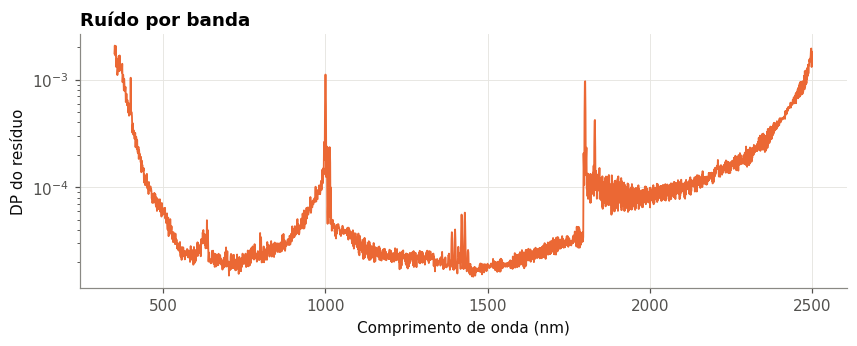

In [3]:
ruido = pp.noise_level(X)
ax = ruido.plot(figsize=(9, 3), color=vz.CATEGORICAL[1])
ax.set(xlabel="Comprimento de onda (nm)", ylabel="DP do resíduo", yscale="log")
ax.set_title("Ruído por banda", loc="left");

In [4]:
X = pp.trim(ds.vnir, 400, 2450)
print(ds.vnir.shape, "->", X.shape)

(6230, 2151) -> (6230, 2051)


## 2. Suavização Savitzky-Golay
Ajusta um polinômio de grau `polyorder` numa janela móvel de `window` bandas. Janela maior =
mais suavização, mas feições estreitas são achatadas. Compare com a média móvel simples.

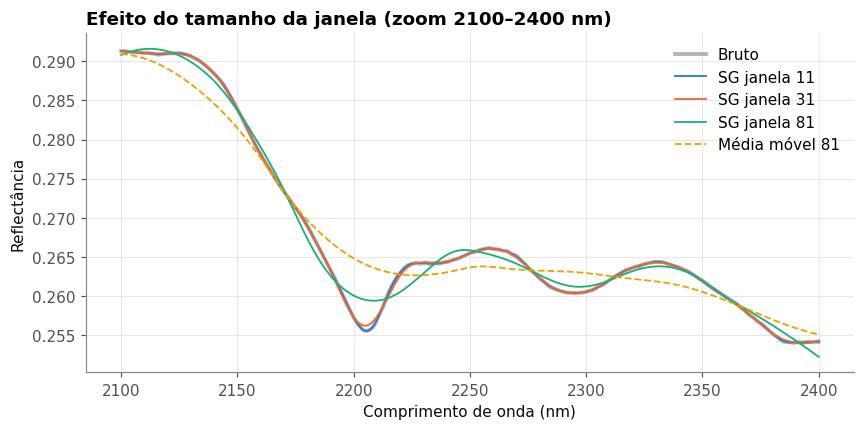

In [5]:
id0 = amostras[0]
zoom = pp.trim(X.loc[[id0]], 2100, 2400)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(zoom.columns, zoom.iloc[0], color="#b5b4ae", lw=2.5, label="Bruto")
for i, w in enumerate([11, 31, 81]):
    ax.plot(zoom.columns, pp.savgol(zoom, window=w, polyorder=2).iloc[0], color=vz.CATEGORICAL[i], label=f"SG janela {w}")
ax.plot(zoom.columns, pp.moving_average(zoom, 81).iloc[0], color=vz.CATEGORICAL[3], ls="--", label="Média móvel 81")
ax.set(xlabel="Comprimento de onda (nm)", ylabel="Reflectância")
ax.legend(); ax.set_title("Efeito do tamanho da janela (zoom 2100–2400 nm)", loc="left");

## 3. Derivadas
A 1ª derivada elimina deslocamentos aditivos (constante) e transforma feições em pares
pico/vale; a 2ª derivada elimina também inclinações lineares e posiciona o **centro da
absorção** num mínimo/máximo nítido. O custo é amplificar o ruído — por isso derivamos
sempre via Savitzky-Golay.

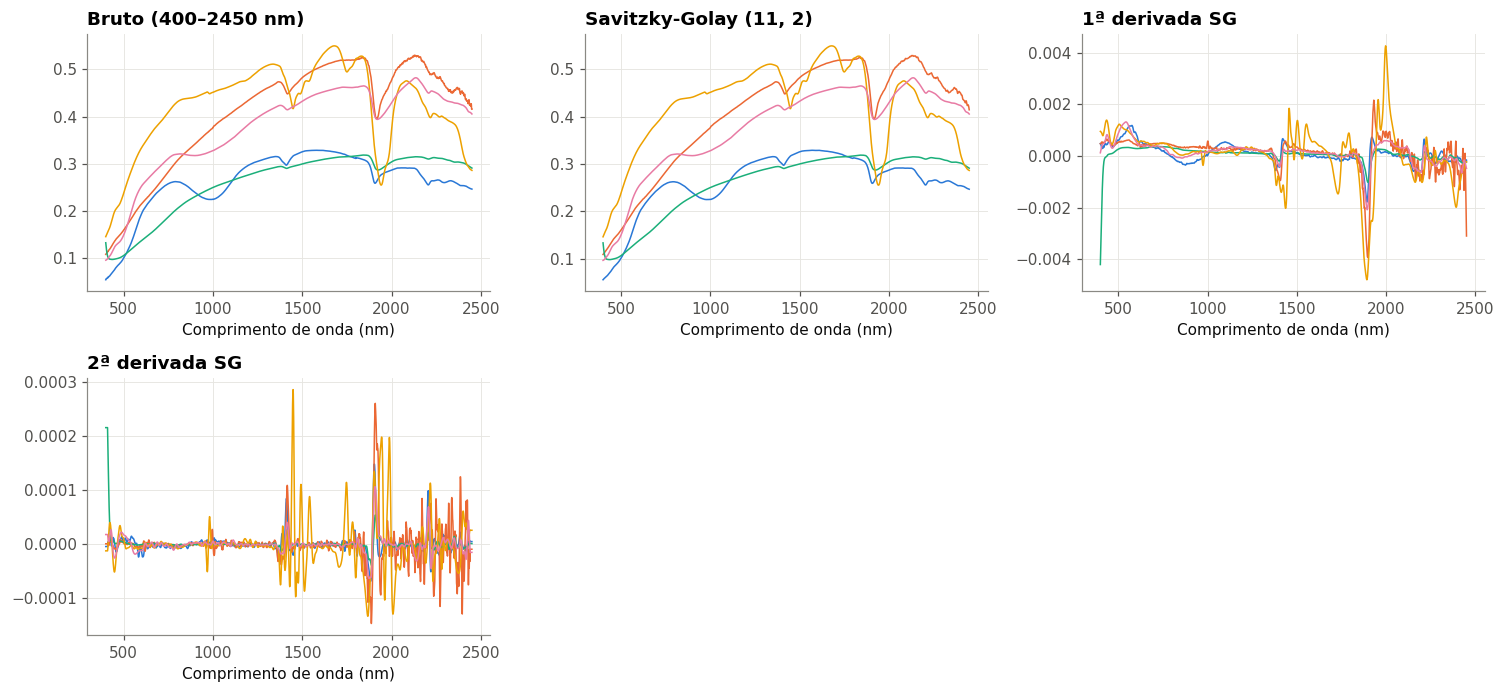

In [6]:
etapas = {
    "Bruto (400–2450 nm)": X,
    "Savitzky-Golay (11, 2)": pp.savgol(X, 11, 2),
    "1ª derivada SG": pp.derivative(X, order=1, window=11),
    "2ª derivada SG": pp.derivative(X, order=2, window=21),
}
fig, axes = vz.plot_processing_steps(etapas, sample_ids=amostras)

## 4. Correções de espalhamento: SNV, MSC e Detrend
- **SNV** — cada espectro menos sua média, dividido pelo seu desvio (não depende das outras amostras).
- **MSC** — regride cada espectro contra a média do conjunto e corrige *(x − a)/b*.
  ⚠️ A referência deve ser aprendida **só no treino** — por isso, na modelagem, usamos a
  classe `pp.MSC()` dentro do `Pipeline` (Aula 5).
- **Detrend** — remove a tendência linear (como no script R) ou polinomial (`degree=2`).

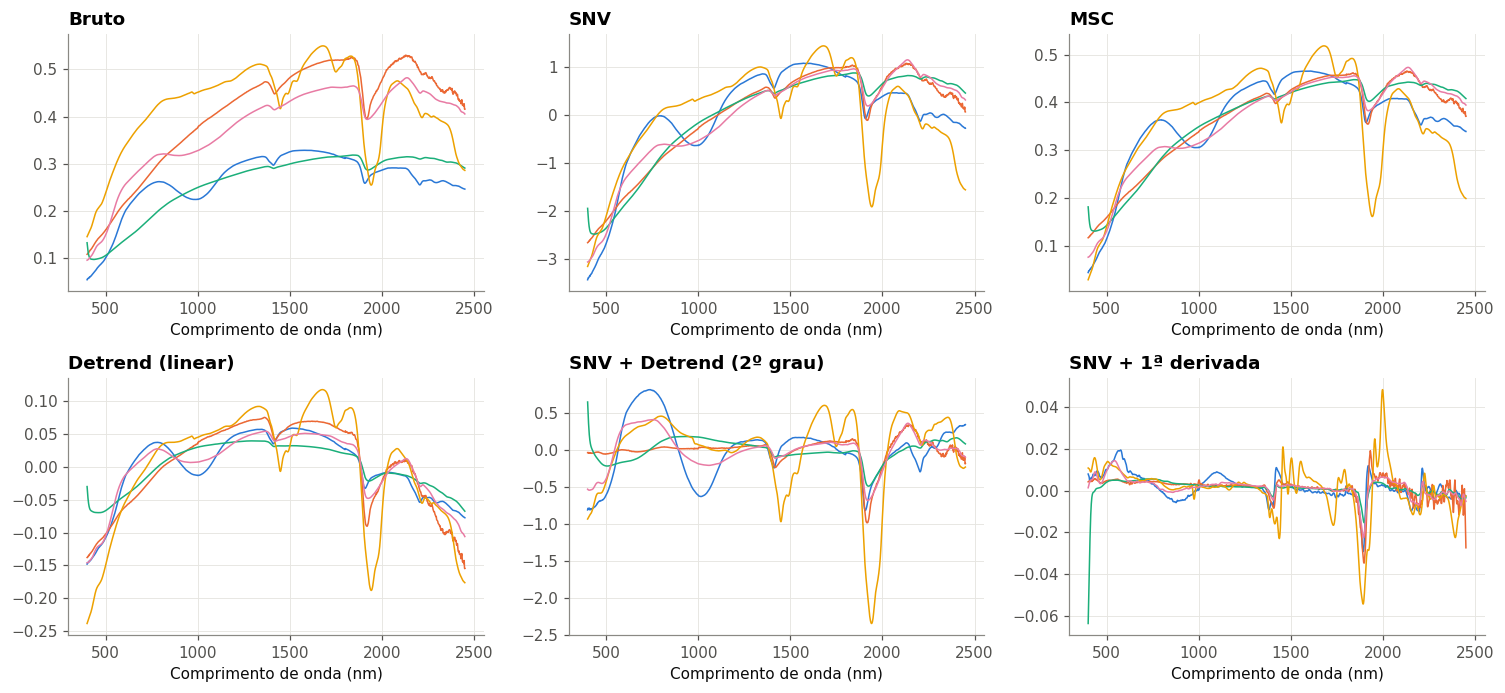

In [7]:
etapas = {
    "Bruto": X,
    "SNV": pp.snv(X),
    "MSC": pp.msc(X),
    "Detrend (linear)": pp.detrend(X),
    "SNV + Detrend (2º grau)": pp.detrend(pp.snv(X), degree=2),
    "SNV + 1ª derivada": pp.derivative(pp.snv(X)),
}
fig, axes = vz.plot_processing_steps(etapas, sample_ids=amostras)

Repare como após SNV/MSC as curvas se **sobrepõem**: a diferença de albedo (em grande parte
física) foi removida e sobram as diferenças de forma (químicas/mineralógicas).

## 5. Remoção do contínuo
O contínuo é o envoltório convexo superior do espectro; dividindo o espectro por ele, cada
feição vira um "vale" entre 0 e 1, comparável entre amostras de albedos diferentes.
A **profundidade da banda** (1 − valor no centro) é um índice semi-quantitativo do mineral.

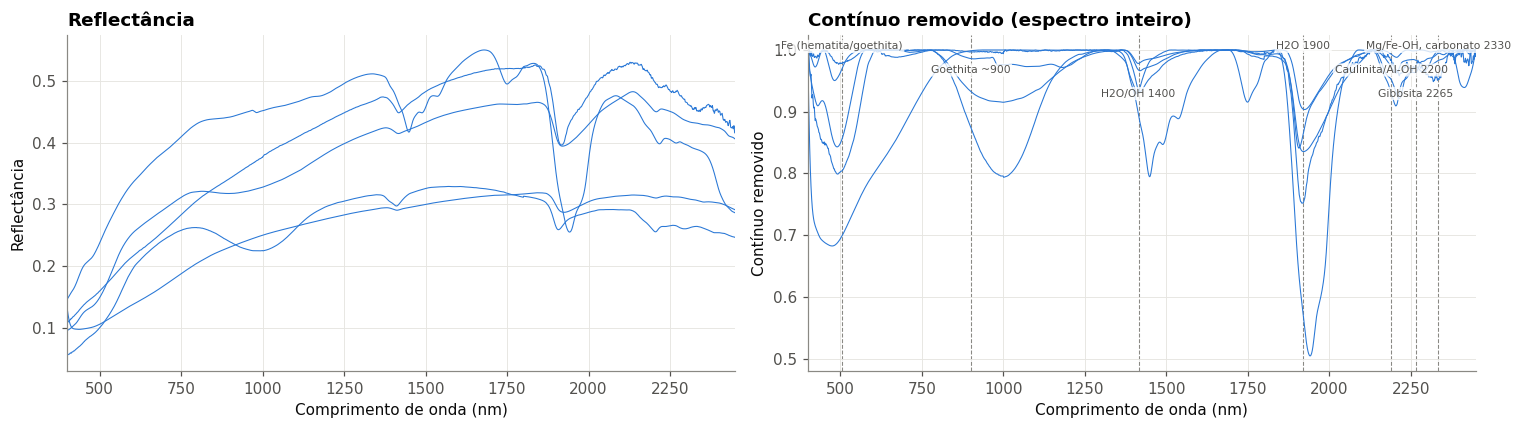

In [8]:
sub = X.loc[amostras]
cr = pp.continuum_removal(sub)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vz.plot_spectra(sub, ax=axes[0], alpha=1, title="Reflectância")
vz.plot_spectra(cr, ax=axes[1], alpha=1, ylabel="Contínuo removido", title="Contínuo removido (espectro inteiro)")
vz.mark_features(axes[1])
fig.tight_layout()

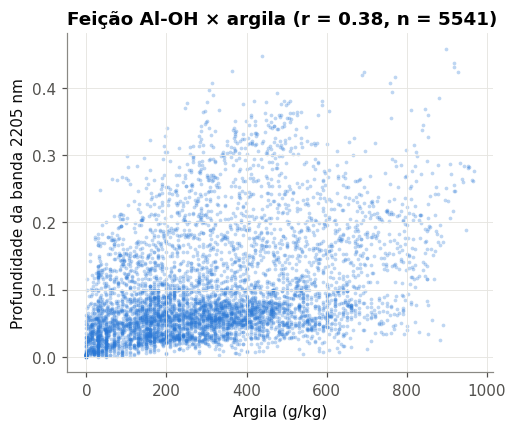

In [9]:
# Profundidade da feição Al-OH (~2205 nm) calculando o contínuo só em 2100-2300 nm
prof = pp.band_depth(ds.vnir, center=2205, window=(2100, 2300))
argila = ds.meta["Clay_gkg"]
ok = argila.notna()
r = np.corrcoef(prof[ok], argila[ok])[0, 1]
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(argila[ok], prof[ok], s=6, alpha=0.3, color=vz.CATEGORICAL[0], lw=0)
ax.set(xlabel="Argila (g/kg)", ylabel="Profundidade da banda 2205 nm")
ax.set_title(f"Feição Al-OH × argila (r = {r:.2f}, n = {ok.sum()})", loc="left");

## 6. Absorbância, binning e reamostragem
- `log10(1/R)` lineariza a relação com concentração.
- **Binning** (média de blocos de bandas) reduz 2051 → ~205 variáveis: modelos mais rápidos,
  perda mínima de informação porque bandas vizinhas são altamente correlacionadas.
- **Reamostragem** compatibiliza espectros de sensores diferentes ou simula bandas de satélite.

absorbância: (6230, 2051) | binning 10: (6230, 205) | reamostrado 50 nm: (6230, 42)


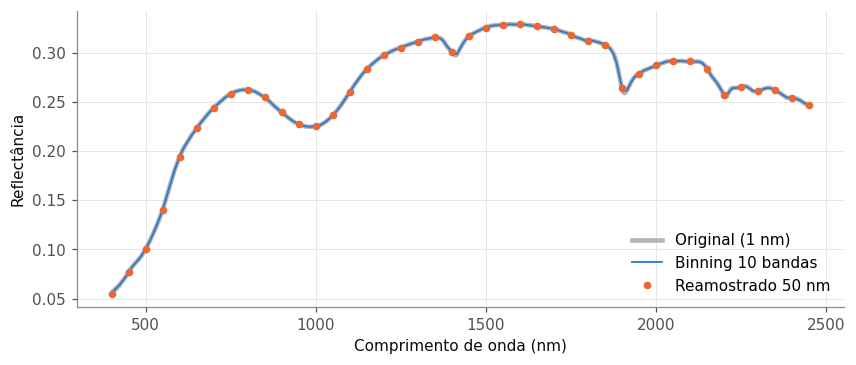

In [10]:
A = pp.reflectance_to_absorbance(X)
B = pp.binning(X, bin_size=10)
R = pp.resample(X, np.arange(400, 2451, 50))
print("absorbância:", A.shape, "| binning 10:", B.shape, "| reamostrado 50 nm:", R.shape)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(X.columns, X.loc[id0], color="#b5b4ae", lw=3, label="Original (1 nm)")
ax.plot(B.columns, B.loc[id0], color=vz.CATEGORICAL[0], lw=1.2, label="Binning 10 bandas")
ax.plot(R.columns, R.loc[id0], "o", color=vz.CATEGORICAL[1], ms=4, label="Reamostrado 50 nm")
ax.set(xlabel="Comprimento de onda (nm)", ylabel="Reflectância"); ax.legend();

## 7. MIR
No MIR, o padrão é **SNV** ou **1ª derivada** (o script R testava raw e SNV). A remoção do
contínuo também funciona — o eixo decrescente em cm⁻¹ é tratado automaticamente.

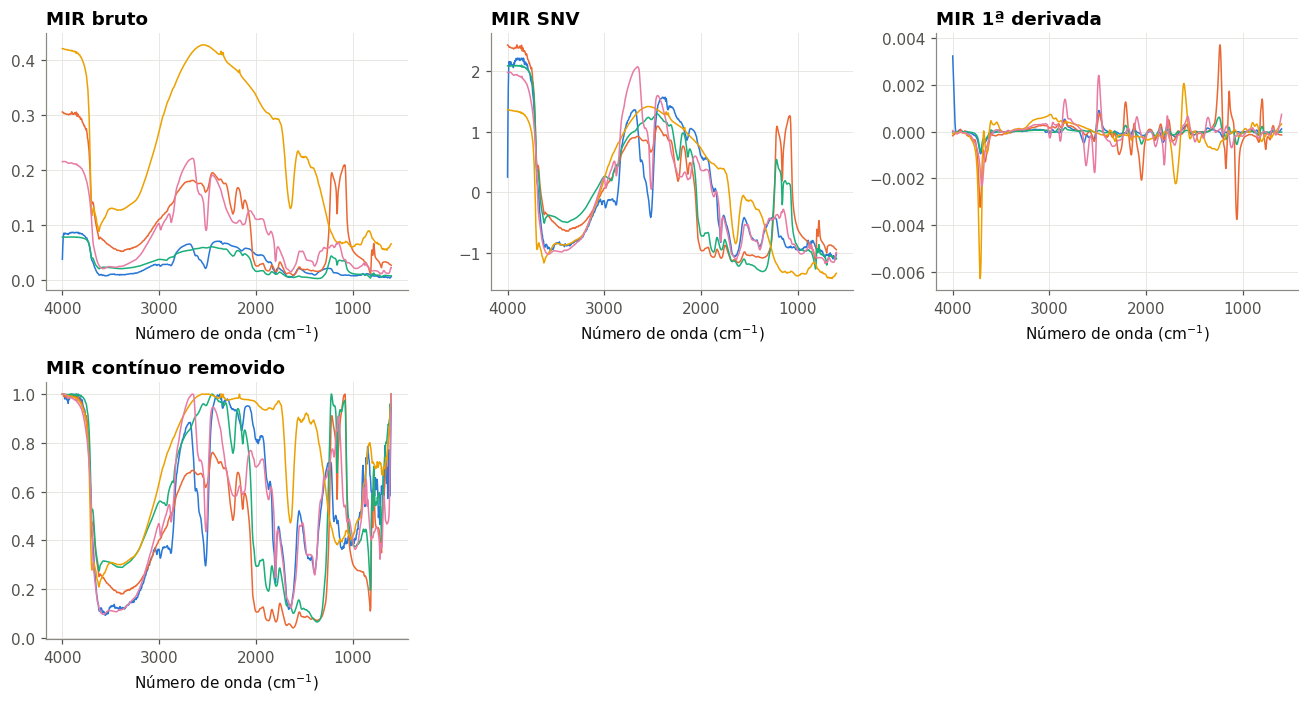

In [11]:
M = ds.mir.loc[amostras]
etapas = {"MIR bruto": M, "MIR SNV": pp.snv(M), "MIR 1ª derivada": pp.derivative(M, 1, 11),
          "MIR contínuo removido": pp.continuum_removal(M)}
fig, axes = vz.plot_processing_steps(etapas, figsize=(12, 6.5))

## 8. Encadeando etapas — o padrão usado nas próximas aulas
Para análise exploratória usamos funções diretas; para **modelagem**, os mesmos passos como
transformadores scikit-learn (`pp.make_preprocessor("snv_sg1d")`), garantindo que nada seja
"aprendido" com o conjunto de teste.

In [12]:
X_proc = pp.derivative(pp.snv(pp.trim(ds.vnir, 400, 2450)), order=1, window=11)
print(X_proc.shape)
print("Opções de pré-processamento para modelos:", list(pp.PREPROCESSORS))

(6230, 2051)
Opções de pré-processamento para modelos: ['raw', 'snv', 'msc', 'detrend', 'sg', 'sg1d', 'sg2d', 'snv_sg1d', 'cr']


## Exercícios
1. Teste janelas 5, 11, 21 e 41 na 1ª derivada. A partir de qual janela a feição de 2205 nm se achata?
2. Calcule a profundidade da banda da **gibbsita** (2265 nm, janela 2230–2300) e correlacione com argila.
3. Repita a seção 5 no MIR para a feição da caulinita (3620 cm⁻¹, janela 3550–3720) com
   `pp.trim` + `pp.continuum_removal`.